# Medical e-procurement: cybersecurity content analysis

Inputs (same folder): `output_data.json`, `cleaned_files.json`, `keywords.json`.
Environment: Python 3.12.3, spaCy 3.8.7 (`en_core_web_md`, `en_core_web_sm` 3.8.0), scikit-learn 1.7.2, numpy 2.1.0, scipy 1.16.2, pandas 2.3.3, gensim 4.4.0, nltk 3.9.2.

In [1]:
import os, platform
# The reported results come from numpy's AVX2 sort path (a CPU without AVX-512). scikit-learn's max_features cut-off and
# argsort() break exact ties with numpy's unstable sort, which numpy dispatches per CPU: on AVX-512 machines ties fall
# differently. Selecting the AVX2 path makes the run identical on any x86 machine. Must be set before numpy is imported.
if platform.machine().lower() in ("x86_64", "amd64"):
    os.environ.setdefault("NPY_DISABLE_CPU_FEATURES",
        "AVX512_SKX AVX512_CLX AVX512_CNL AVX512_ICL AVX512_SPR AVX512F AVX512CD AVX512VL AVX512BW AVX512DQ")

import json, re
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import nltk, spacy
from spacy.lang.en.stop_words import STOP_WORDS
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import NMF
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

nltk.download("stopwords", quiet=True)
nltk.download("punkt_tab", quiet=True)

raw = pd.read_json("../Step 5.1 ConvertToJson/output_data.json", orient="records")
cleaned = pd.read_json("../Step 5.2 CleanData/cleaned_files.json", orient="records")
keywords = json.load(open("../Step 5.3 CybersecurityDictionary/keywords.json"))

def clean(text):
    patterns = [
        r'TECHNICAL SPECIFICATION(?: AND GENERAL POINTS)?(?: Department of [A-Za-z\s]+)?(?: ITEM NAME [A-Za-z\s]+)?',
        r'DEPARTMENT OF [A-Z\s]+(?: ENT)?(?: ALL INDIA INSTITUTE OF MEDICAL SCIENCES)?(?:,? [A-Z\s,]+)?',
        r'ALL INDIA INSTITUTE OF MEDICAL SCIENCES,?(?: [A-Z\s,]+)?',
        r'NEW DELHI-\d, INDIA', r'Sr\. No', r'Page \d+ of \d+', r'T\.No\.\d+CNCNS\d+St',
        r'\b[A-Za-z]\.\s*', r'\d{2}\s[a-z]', r'\d+\.', r'01No\.02Nos', r'\d*',
    ]
    text = text.encode("ascii", "ignore").decode("ascii")
    text = re.sub(r"\r\n|\r|\n", " ", text)
    for p in patterns:
        text = re.sub(p, "", text, flags=re.IGNORECASE)
    return text.strip()

spec = raw["technical_specification"].fillna("").astype(str).map(clean)
print(len(raw), "documents |", len(keywords), "security keywords")

760 documents | 102 security keywords


## 1. Security content presence

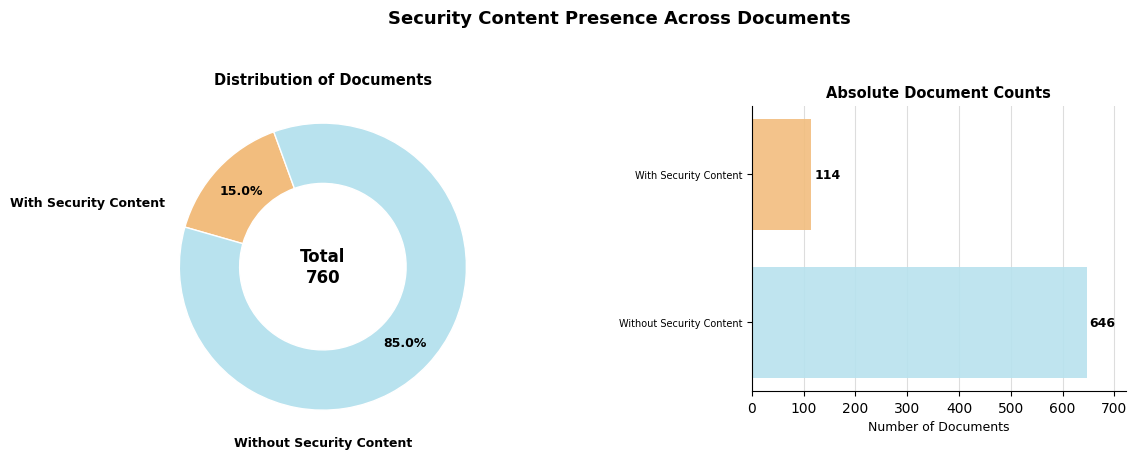

In [2]:
has_security = spec.str.lower().map(lambda t: any(k in t for k in keywords))
n_with, n_without = int(has_security.sum()), int((~has_security).sum())
total = n_with + n_without
orange, blue = "#f2bd7e", "#b8e2ee"

fig = plt.figure(figsize=(11, 4.6))
fig.suptitle("Security Content Presence Across Documents", fontsize=13, fontweight="bold", y=1.0)
a1 = fig.add_axes([0.02, 0.05, 0.42, 0.78]); a2 = fig.add_axes([0.62, 0.17, 0.34, 0.62])
a1.pie([n_with, n_without], colors=[orange, blue], startangle=110, autopct="%1.1f%%", pctdistance=0.78,
       wedgeprops=dict(width=0.42, edgecolor="white"), textprops=dict(fontsize=9, fontweight="bold"))
a1.text(0, 0, f"Total\n{total}", ha="center", va="center", fontsize=12, fontweight="bold")
a1.text(-1.1, 0.45, "With Security Content", ha="right", va="center", fontsize=9, fontweight="bold")
a1.text(0, -1.18, "Without Security Content", ha="center", va="top", fontsize=9, fontweight="bold")
a1.set_title("Distribution of Documents", fontsize=10.5, fontweight="bold", pad=2)
a2.barh([1, 0], [n_with, n_without], color=[orange, blue], height=0.75, alpha=0.9)
a2.set_yticks([1, 0]); a2.set_yticklabels(["With Security Content", "Without Security Content"], fontsize=7)
for y, v in [(1, n_with), (0, n_without)]:
    a2.text(v + total * 0.008, y, str(v), va="center", fontsize=9, fontweight="bold")
a2.set_xlim(0, total * 0.95); a2.set_xlabel("Number of Documents", fontsize=9)
a2.set_title("Absolute Document Counts", fontsize=10.5, fontweight="bold")
a2.grid(axis="x", color="#dddddd", lw=0.8); a2.set_axisbelow(True)
for s in ("top", "right"): a2.spines[s].set_visible(False)
fig.savefig("security_presence.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Top TF-IDF terms

In [3]:
nlp_md, nlp_sm = spacy.load("en_core_web_md"), spacy.load("en_core_web_sm")

# sentences whose lemmas contain a security keyword
security_text = [" ".join(s.text for s in d.sents if any(k in " ".join(t.lemma_ for t in s) for k in keywords))
                 for d in nlp_md.pipe(spec.tolist(), batch_size=8)]

extra_stopwords = {"device", "feature", "patch", "upgrade", "minimum", "provide", "late", "report", "follow", "light",
                   "time", "plate", "page", "aiims", "include", "improvement", "shall", "year", "free", "possible",
                   "cassette", "pre", "tender", "offer", "upto"}
stop = STOP_WORDS | extra_stopwords

combined_text = [" ".join(t.lemma_.lower() for t in d
                          if t.lemma_.lower() not in stop and not t.is_punct and len(t.text) > 1)
                 for d in nlp_sm.pipe(security_text, batch_size=8)]

SKIP = {"submit", "monitor", "high", "display", "control"}

def tfidf_scores(docs, **kw):
    v = TfidfVectorizer(**kw)
    X = v.fit_transform(docs)
    s = pd.Series(X.sum(axis=0).A1, index=v.get_feature_names_out())
    s = s[~s.index.str.contains(" ")].sort_values(ascending=False)
    return s.drop(index=[w for w in SKIP if w in s.index])

L = {"security": tfidf_scores(combined_text, ngram_range=(1, 2), max_features=100),
     "tech": tfidf_scores(cleaned["technical_specification"].fillna(""), ngram_range=(1, 2)),
     "content": tfidf_scores(cleaned["content"].fillna(""), ngram_range=(1, 2))}

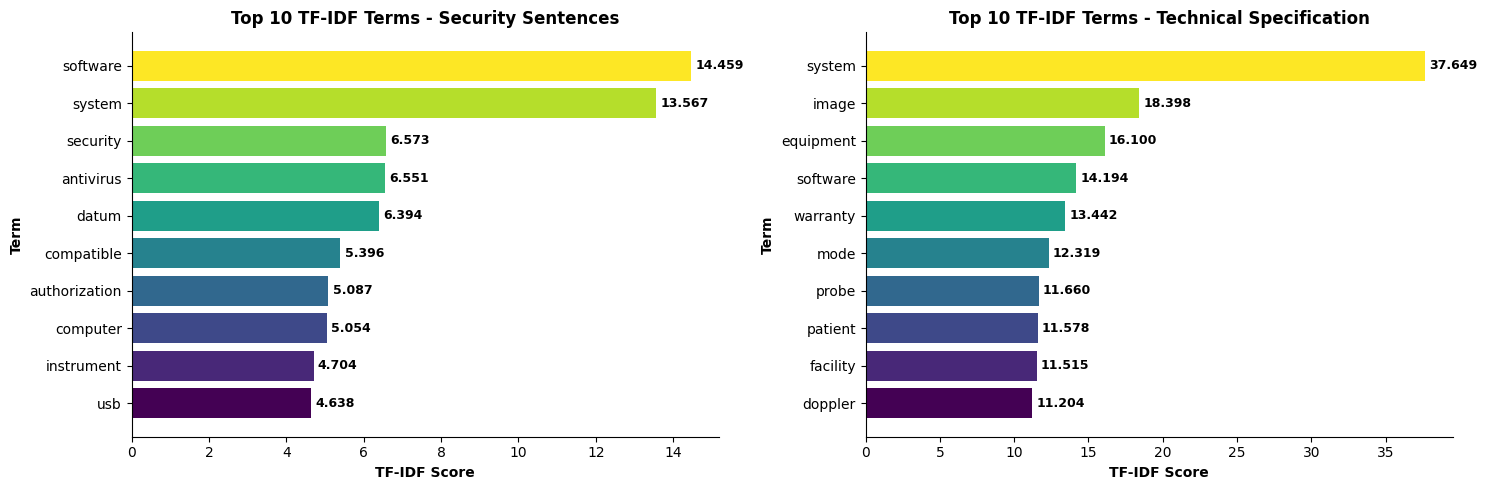

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, key, title in [(axes[0], "security", "Security Sentences"), (axes[1], "tech", "Technical Specification")]:
    s = L[key].head(10)[::-1]
    bars = ax.barh(s.index, s.values, color=plt.cm.viridis(np.linspace(0, 1, len(s))))
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9, fontweight="bold")
    ax.set_title(f"Top 10 TF-IDF Terms - {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("TF-IDF Score", fontweight="bold"); ax.set_ylabel("Term", fontweight="bold")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
plt.tight_layout()
fig.savefig("top_tfidf_terms.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Specificity vs function of terms

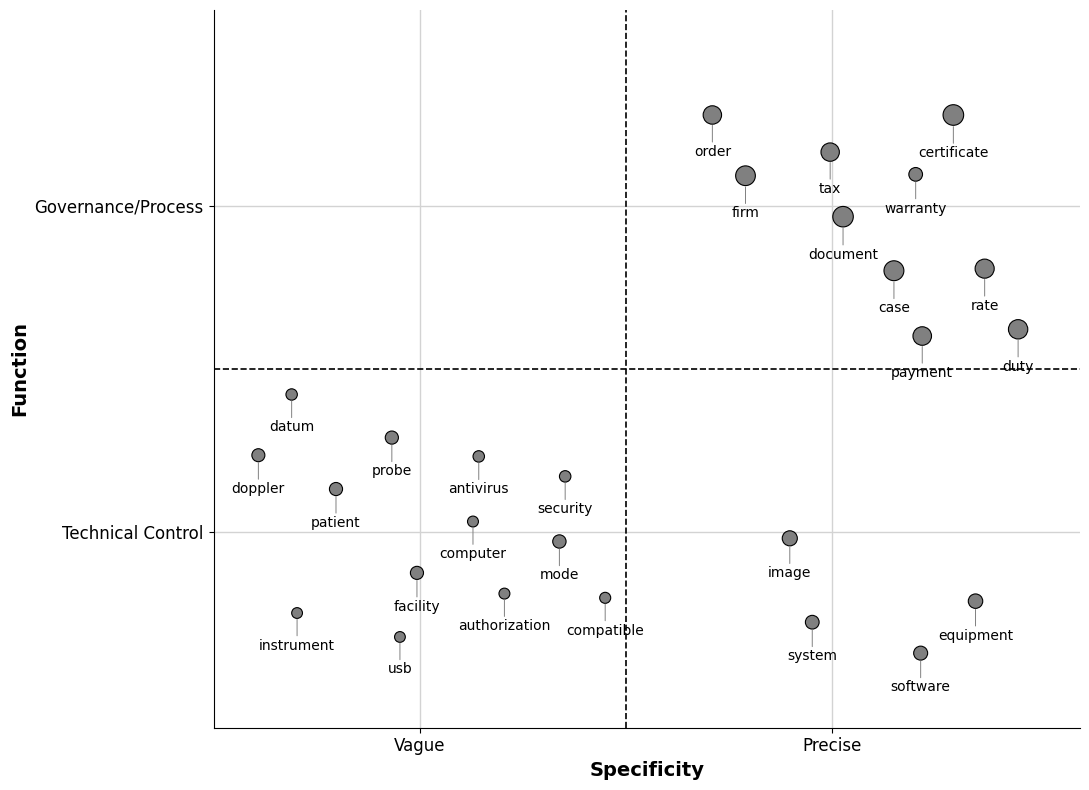

In [5]:
N, SEED = 10, 42

q = pd.DataFrame([{"term": w, "tfidf": s} for k in L for w, s in L[k].head(N).items()]).drop_duplicates("term").reset_index(drop=True)
q["side"] = np.where(q["tfidf"] >= q["tfidf"].median(), "Precise", "Vague")

def rank(k, w):
    return list(L[k].index).index(w) + 1 if w in L[k].index else len(L[k]) + 1

q["group"] = ["Governance/Process" if rank("content", w) < min(rank("tech", w), rank("security", w))
              else "Technical Control" for w in q["term"]]
q.loc[q["term"] == "warranty", "group"] = "Governance/Process"

# jitter points inside their quadrant, then push overlapping points apart
rng = np.random.default_rng(SEED)
cx, cy = np.where(q["side"] == "Precise", 2, 1), np.where(q["group"] == "Governance/Process", 2, 1)
x, y = cx + rng.uniform(-0.4, 0.4, len(q)), cy + rng.uniform(-0.4, 0.4, len(q))
for _ in range(600):
    moved = False
    for i in range(len(x)):
        for j in range(i + 1, len(x)):
            dx, dy = (x[i] - x[j]) / 0.22, (y[i] - y[j]) / 0.20
            d = np.hypot(dx, dy)
            if d < 1:
                if d < 1e-6: dx, dy, d = rng.normal(), rng.normal(), 1.0
                p = (1 - d) / 4
                x[i] += p * dx / d * 0.22; x[j] -= p * dx / d * 0.22
                y[i] += p * dy / d * 0.20; y[j] -= p * dy / d * 0.20
                moved = True
    x, y = np.clip(x, cx - 0.45, cx + 0.45), np.clip(y, cy - 0.45, cy + 0.45)
    if not moved: break

sizes = np.interp(q["tfidf"], (q["tfidf"].min(), q["tfidf"].max()), (60, 220))
fig, ax = plt.subplots(figsize=(11, 8))
ax.set_axisbelow(True); ax.grid(True, color="lightgray", lw=1)
ax.scatter(x, y, s=sizes, c="gray", edgecolors="black", linewidths=0.8, zorder=3)
for w, xi, yi, s in zip(q["term"], x, y, sizes):
    ax.annotate(w, (xi, yi), xytext=(0, -(np.sqrt(s / np.pi) + 14)), textcoords="offset points", ha="center", va="top",
                fontsize=10, zorder=4, arrowprops=dict(arrowstyle="-", color="gray", lw=0.7, shrinkA=0, shrinkB=np.sqrt(s / np.pi)))
ax.axhline(1.5, color="black", ls="--", lw=1.2, zorder=2); ax.axvline(1.5, color="black", ls="--", lw=1.2, zorder=2)
ax.set_xlim(0.5, 2.6); ax.set_ylim(0.4, 2.6)
ax.set_xticks([1, 2]); ax.set_xticklabels(["Vague", "Precise"], fontsize=12)
ax.set_yticks([1, 2]); ax.set_yticklabels(["Technical Control", "Governance/Process"], fontsize=12)
ax.set_xlabel("Specificity", fontsize=14, fontweight="bold"); ax.set_ylabel("Function", fontsize=14, fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig("specificity_function.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. NMF topics and coherence

In [6]:
vec = TfidfVectorizer(stop_words=list(set(stopwords.words("english"))))
X = vec.fit_transform(cleaned["technical_specification"].fillna(""))
names = vec.get_feature_names_out()
nmf = NMF(n_components=9, random_state=42, beta_loss="frobenius").fit(X)
top_words = lambda comp, n: [names[i] for i in comp.argsort()[:-n - 1:-1]]

topic_names = ["Imaging and Camera Systems", "Ultrasound and Doppler Systems", "Equipment Maintenance",
               "Patient Monitoring Systems", "PCR and Analysis Systems", "Microscopy Systems",
               "Surgical Navigation Systems", "Medical Department Equipment", "Surgical Instruments"]
pd.DataFrame({"Topic": range(1, 10), "Topic Name": topic_names,
              "Keywords": [", ".join(top_words(c, 8)) for c in nmf.components_]}).style.hide(axis="index")

Topic,Topic Name,Keywords
1,Imaging and Camera Systems,"video, image, camera, light, system, definition, output, high"
2,Ultrasound and Doppler Systems,"doppler, transducer, imaging, system, mhz, image, mode, probe"
3,Equipment Maintenance,"equipment, site, maintenance, warranty, modification, preventive, hospital, basis"
4,Patient Monitoring Systems,"monitor, monitoring, pressure, ecg, alarm, patient, display, parameter"
5,PCR and Analysis Systems,"system, sample, pcr, test, temperature, plate, analysis, instrument"
6,Microscopy Systems,"microscope, fluorescence, stage, camera, filter, objective, plan, light"
7,Surgical Navigation Systems,"system, navigation, probe, instrument, registration, surgery, software, image"
8,Medical Department Equipment,"enquiry, patho, optho, common, surgery, micro, library, radiology"
9,Surgical Instruments,"forceps, diameter, telescope, sheath, jaw, tip, straight, bipolar"


In [7]:
def coherence(topics, texts):
    d = Dictionary(texts)
    topics = [[w for w in t if w in d.token2id] for t in topics]
    return round(CoherenceModel(topics=topics, texts=texts, dictionary=d, coherence="c_v").get_coherence(), 4)

tech_texts = [t.lower().split() for t in cleaned["technical_specification"].fillna("")]
tech_coherence = coherence([top_words(c, 10) for c in nmf.components_], tech_texts)

sec_vec = TfidfVectorizer(ngram_range=(1, 2), max_features=100)
sec_X = sec_vec.fit_transform(combined_text)
sec_names = sec_vec.get_feature_names_out()
sec_nmf = NMF(n_components=10, init="nndsvd", random_state=42, max_iter=200).fit(sec_X)
sec_topics = [[sec_names[i] for i in c.argsort()[:-11:-1]] for c in sec_nmf.components_]
sec_coherence = coherence(sec_topics, [word_tokenize(t.lower()) for t in combined_text if t.strip()])

pd.Series({"Technical specification": tech_coherence, "Security sentences": sec_coherence}, name="c_v").to_frame()

,c_v
Technical specification,0.7027
Security sentences,0.4228


## 5. Referenced standards

In [20]:
std = Counter(f"{b} {n}" for t in raw["content"].fillna("")
              for b, n in re.findall(r"\b(?:(?:ISO|IEC)\s*[/.]\s*)?(ISO|IEC)\s(\d+(?::\d+)?)", t))

# only the category grouping 
iso_groups = {
    "Quality Management": ["ISO 9001", "ISO 9001:2015", "ISO 9001:2008", "ISO 9001:2000"],
    "Medical Devices": ["ISO 13485", "ISO 13485:2016", "ISO 13485:2003", "ISO 10993", "ISO 14971"],
    "RFID Standards": ["ISO 14443", "ISO 15693", "ISO 18000:3"],
    "Information Security": ["ISO 27001", "ISO 27002"],
    "Miscellaneous": ["ISO 4628", "ISO 7153", "ISO 60", "ISO 4090", "ISO 5", "ISO 28560", "ISO 7376:2009"]}
iec_groups = {
    "Electrical Equipment": ["IEC 60601", "IEC 601", "IEC 60603", "IEC 950"],
    "Communication": ["IEC 11801", "IEC 14443", "IEC 61034"],
    "Safety Standards": ["IEC 62368", "IEC 60529", "IEC 60068", "IEC 60364", "IEC 60332"],
    "Other Standards": ["IEC 61010", "IEC 17025:2005", "IEC 60794", "IEC 529"]}

def std_table(groups, kind):
    return pd.DataFrame([(c, s, std[s]) for c, ss in groups.items() for s in ss],
                        columns=["Category", f"{kind} Standard", "Count"]).style.hide(axis="index")

std_table(iso_groups, "ISO")

Category,ISO Standard,Count
Quality Management,ISO 9001,24
Quality Management,ISO 9001:2015,16
Quality Management,ISO 9001:2008,6
Quality Management,ISO 9001:2000,3
Medical Devices,ISO 13485,7
Medical Devices,ISO 13485:2016,3
Medical Devices,ISO 13485:2003,1
Medical Devices,ISO 10993,2
Medical Devices,ISO 14971,2
RFID Standards,ISO 14443,10


In [21]:
std_table(iec_groups, "IEC")

Category,IEC Standard,Count
Electrical Equipment,IEC 60601,112
Electrical Equipment,IEC 601,23
Electrical Equipment,IEC 60603,5
Electrical Equipment,IEC 950,4
Communication,IEC 11801,12
Communication,IEC 14443,5
Communication,IEC 61034,3
Safety Standards,IEC 62368,3
Safety Standards,IEC 60529,3
Safety Standards,IEC 60068,2


In [10]:
pd.Series({a: int(raw["content"].str.findall(rf"\b{a}\b").str.len().sum()) for a in ["CE", "FDA", "ISO", "IEC", "HIPAA"]},
          name="Mentions").to_frame()

,Mentions
CE,1336
FDA,988
ISO,662
IEC,497
HIPAA,8


In [11]:
# Section 6: prevalence results computed from keywords.json and the loaded data only
spec_l = spec.str.lower()                                   # technical specification (text used for has_security)
cont_l = raw["content"].fillna("").str.lower()              # full tender text

match = pd.DataFrame({k: spec_l.str.contains(re.escape(k)) for k in keywords})   # as-written keyword test
n_docs, kw_docs = len(match), match.sum().sort_values(ascending=False)

top_terms = pd.Index(L["tech"].head(25).index.union(L["content"].head(25).index))
prev = pd.DataFrame({"spec %": [100 * spec_l.str.contains(rf"\b{t}").mean() for t in top_terms],
                     "full tender %": [100 * cont_l.str.contains(rf"\b{t}").mean() for t in top_terms]}, index=top_terms).round(1)

crypt_cols = [k for k in keywords if "crypt" in k.lower()]

found = pd.DataFrame([(m.group(1), m.group(2), i) for i, t in raw["content"].fillna("").items()
                      for m in re.finditer(r"\b(ISO|IEC)(?:\s*/\s*(?:ISO|IEC))?[\s\-]*(\d+)", t)], columns=["body", "num", "doc"])
std2 = found.groupby(["body", "num"]).size()
infosec = found[found["num"].str.startswith("27")]

print(f"Tenders with security content: {int(match.any(axis=1).sum())}/{n_docs} = {100 * match.any(axis=1).mean():.1f}%")
print(f"Dictionary keywords matched: {int((kw_docs > 0).sum())} of {len(keywords)}")
print(kw_docs[kw_docs > 0].to_string())
print("\nTop TF-IDF terms, % of tenders mentioning them:")
print(prev.loc[[t for t in ("warranty", "equipment", "maintenance") if t in prev.index]])
print(f"\nEncryption: dictionary group {100 * match[crypt_cols].any(axis=1).mean():.1f}% | text 'encrypt' in specification {100 * spec_l.str.contains('encrypt').mean():.1f}%")
print("\nISO/IEC 27xxx mentions:", infosec.groupby(["body", "num"]).size().to_dict(), "| tenders:", infosec["doc"].nunique(),
      f"| {100 * len(infosec) / len(found):.2f}% of {len(found)} numbered ISO/IEC mentions")
print("IEC 60332 mentions:", int(std2.get(("IEC", "60332"), 0)))

Tenders with security content: 114/760 = 15.0%
Dictionary keywords matched: 20 of 102
virus                 30
patch                 24
authorization         22
restore               21
asset                 20
authentication        12
antivirus software    11
encode                 7
firewall               6
risk assessment        5
access control         4
whitelist              2
blacklist              2
cybersecurity          1
encryption key         1
data integrity         1
bug                    1
outsourcing            1
ransomware             1
security control       1

Top TF-IDF terms, % of tenders mentioning them:
             spec %  full tender %
warranty       57.1           99.1
equipment      55.9           98.3
maintenance    32.6           94.3

Encryption: dictionary group 0.1% | text 'encrypt' in specification 1.6%

ISO/IEC 27xxx mentions: {('ISO', '27001'): 4} | tenders: 1 | 0.81% of 494 numbered ISO/IEC mentions
IEC 60332 mentions: 2
